> **Demonstração pública:** 253 VMs sintéticas e 221 com métricas completas. Contagens de anomalias/alertas resultam da execução e **não devem ser confundidas com dados operacionais**.


# AIOps #03 — Da anomalia à fila de investigação

**Continuação do laboratório #02.** Use a base pública sintética por padrão, ou os dados operacionais pseudonimizados quando disponíveis localmente. Objetivo: separar indícios estatísticos de limiares operacionais e criar uma fila explicável **para revisão humana**, não autorizar ações automáticas.

> A planilha e os CSVs operacionais permanecem **fora do GitHub**. Uma VM atípica não é, por si só, um incidente. Prioridade final exige criticidade, janelas de manutenção e validação do responsável.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks': root=root.parent
privado=root/'data'/'pseudonimizados'
publico=root/'data'/'public_demo'
p=publico if all((privado/f).is_file() for f in ['vms_inventario.csv','hist_cpu.csv','hist_mem.csv','hist_disk.csv','cpu_acima_th.csv','mem_acima_th.csv','disk_vms_acima_th.csv']) else publico
print('ORIGEM:', 'DADOS OPERACIONAIS PRIVADOS' if p==privado else 'DEMONSTRAÇÃO 100% SINTÉTICA')
requeridos=['vms_inventario.csv','hist_cpu.csv','hist_mem.csv','hist_disk.csv','cpu_acima_th.csv','mem_acima_th.csv','disk_vms_acima_th.csv']
faltando=[f for f in requeridos if not (p/f).exists()]
if faltando: raise FileNotFoundError(f'Arquivos locais ausentes em {p}: {faltando}')
inv=pd.read_csv(p/'vms_inventario.csv'); cpu=pd.read_csv(p/'hist_cpu.csv'); mem=pd.read_csv(p/'hist_mem.csv'); disk=pd.read_csv(p/'hist_disk.csv')
assert inv.vm.is_unique
print(f'Inventário: {len(inv)} VMs | CPU: {len(cpu)} | memória: {len(mem)} | disco: {len(disk)} registros')

ORIGEM: DEMONSTRAÇÃO 100% SINTÉTICA
Inventário: 253 VMs | CPU: 6188 | memória: 6188 | disco: 6188 registros


## 1. Transformar histórico em indicadores por VM
Cada linha do histórico é uma observação. `groupby("vm")` produz média, máximo, desvio-padrão e contagem de observações. Isso é **resumo do passado**, não forecast.

In [3]:
def agregados(df, prefixo):
    return df.groupby('vm').used_pct.agg(['mean','max','std','count']).rename(columns={x:f'{prefixo}_{x}' for x in ['mean','max','std','count']})
quadro=inv.merge(agregados(cpu,'cpu'),on='vm',how='left').merge(agregados(mem,'mem'),on='vm',how='left')
quadro=quadro.merge(disk.groupby('vm').used_pct.max().rename('disk_max'),on='vm',how='left')
atributos=['cpu_mean','cpu_max','cpu_std','mem_mean','mem_max','mem_std','disk_max']
base=quadro.loc[quadro[atributos].notna().all(axis=1)].copy()
print('Elegíveis:',len(base),'| faltantes:',len(inv)-len(base))

Elegíveis: 221 | faltantes: 32


## 2. Reproduzir o detector do #02
O `RobustScaler` normaliza indicadores com menor sensibilidade aos valores extremos. O `IsolationForest` atribui um sinal de anomalia a aproximadamente 5% dos registros elegíveis, **por configuração** (`contamination=0.05`); não é a taxa real de incidentes.

In [4]:
X=RobustScaler().fit_transform(base[atributos])
modelo=IsolationForest(n_estimators=250, contamination=0.05, random_state=42)
base['anomalia']=modelo.fit_predict(X)==-1
base['score_anomalia']=-modelo.score_samples(X)
print('Anomalias estatísticas:',int(base.anomalia.sum()))

Anomalias estatísticas: 11


## 3. Cruzar alertas observados
Um limiar é um alerta de regra, não uma confirmação de indisponibilidade. O conjunto é derivado dos CSVs de ocorrências de CPU, memória e disco, sem contar cada linha como uma VM distinta.

In [5]:
alertas={'cpu':pd.read_csv(p/'cpu_acima_th.csv'),'mem':pd.read_csv(p/'mem_acima_th.csv'),'disk':pd.read_csv(p/'disk_vms_acima_th.csv')}
for tipo,df in alertas.items():
    base[f'{tipo}_limiar']=base.vm.isin(df.vm)
    base[f'{tipo}_ocorrencias']=base.vm.map(df.groupby('vm').size()).fillna(0).astype(int)
base['limiar_qualquer']=base[[f'{x}_limiar' for x in alertas]].any(axis=1)
base['classe_triagem']=np.select([base.anomalia & base.limiar_qualquer,base.limiar_qualquer,base.anomalia],['Anomalia + limiar','Somente limiar','Somente anomalia'],default='Monitoramento')
print(base.classe_triagem.value_counts().to_string())

classe_triagem
Monitoramento        175
Somente limiar        35
Anomalia + limiar      8
Somente anomalia       3


## 4. Construir fila **explicável**, sem desligar ou alterar VMs
A regra usa a convergência de **dois sinais independentes** para ordenar a investigação. É uma fila técnica preliminar, não uma escala formal de severidade P0–P4. Sem criticidade de negócio e janela temporal, não existe decisão operacional automática.

In [6]:
base['fila']=np.select([base.anomalia & base.limiar_qualquer,base.limiar_qualquer,base.anomalia],['REVISAR_COM_PRIORIDADE','REVISAR_LIMIAR','REVISAR_ANOMALIA'],default='MONITORAR')
resumo=base.groupby(['fila','classe_triagem']).size().rename('vms').reset_index()
print(resumo.to_string(index=False))
assert resumo.vms.sum()==len(base)
print('Ações automáticas executadas: 0')

                  fila    classe_triagem  vms
             MONITORAR     Monitoramento  175
      REVISAR_ANOMALIA  Somente anomalia    3
REVISAR_COM_PRIORIDADE Anomalia + limiar    8
        REVISAR_LIMIAR    Somente limiar   35
Ações automáticas executadas: 0


## 5. Gráficos agregados para compartilhar
Não exportamos nome de VM, histórico individual ou score por VM. Isso diminui exposição, mas não substitui avaliação de privacidade antes de publicar.

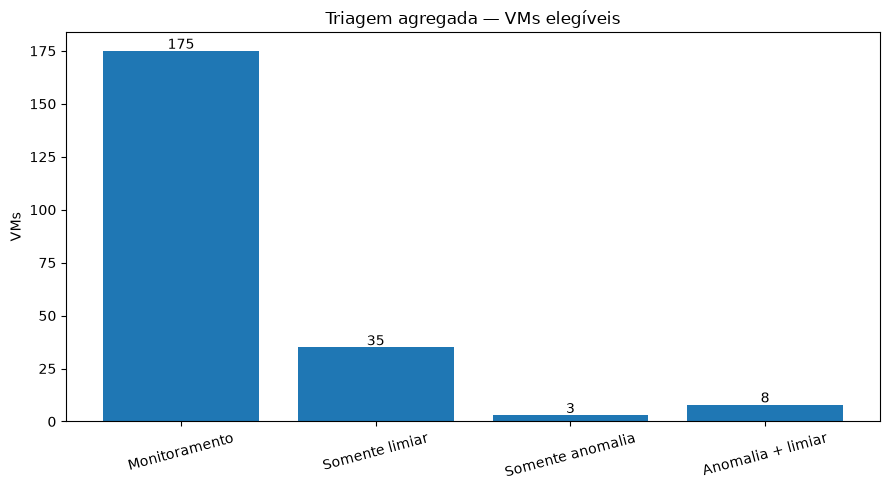

Total elegível: 221 | fora da análise por dados ausentes: 32


In [7]:
cont=base.classe_triagem.value_counts().reindex(['Monitoramento','Somente limiar','Somente anomalia','Anomalia + limiar'],fill_value=0)
fig,ax=plt.subplots(figsize=(9,5))
rects=ax.bar(cont.index,cont.values)
for rect,val in zip(rects,cont.values): ax.text(rect.get_x()+rect.get_width()/2,rect.get_height()+1,str(val),ha='center')
ax.set(title='Triagem agregada — VMs elegíveis',ylabel='VMs');ax.tick_params(axis='x',labelrotation=15)
plt.tight_layout();plt.show()
print('Total elegível:',int(cont.sum()),'| fora da análise por dados ausentes:',len(inv)-len(base))

## 6. Interpretação e validação humana
1. **Anomalia + limiar:** investigar primeiro, verificando incidência temporal, criticidade, aplicação e manutenção.
2. **Somente limiar:** confirmar duração, recorrência e thresholds apropriados.
3. **Somente anomalia:** procurar mudança de padrão e falsos positivos.
4. **Monitoramento:** manter observabilidade; ausência de alerta não prova saúde.

**Limites:** base de um cluster; percentuais históricos; sem validação de incidentes reais, rótulos de causa raiz ou carga futura. Não publicar os CSVs nem outputs por VM.